In [1]:
import numpy as np
import pandas as pd
import math
import os
import sys

# Cut into periodic boundary
Assuming that the local structure can either be Rhombohedral or Cubic only (To be verified)
Process cfg file then convert to data file
- Step 1: define the center.
Find the nearest Fe atom, and make the Fe atom the center.
- Step 2: define the Rhombohedral or Cubic lattice.
Find the nearest Mn atoms around the center

In [2]:
# Separate the cfg file into section
# Load Each section one by one
def load_cfg(filename):
    try:
        with open(filename, 'r') as file:
            lines = file.readlines()[4:-5]  # Read from the 5th line onwards 
        
        # Split each line into separate numbers
        numbers = []
        for line in lines:
            line_numbers = [float(num) for num in line.split()]  # Assuming numbers are floats
            numbers.append(line_numbers)
        
        # Convert the list of lists into a NumPy array
        return np.array(numbers)
    
    except FileNotFoundError:
        print(f"Error: File '{filename}' not found.")
    except IsADirectoryError:
        print(f"Error: '{filename}' is a directory, not a file.")
    except IOError:
        print(f"Error: Could not read file '{filename}'.")
    except Exception as e:
        print(f"Error: {e}")


In [3]:
file = './section_1.cfg'
data = load_cfg(file)

### Step 1: redefine the center

In [4]:
def distance_3d(point1, point2):
    return np.linalg.norm(point1 - point2)

def find_nearest_atom(data, origin, target_types):
    target_atoms = data[np.isin(data[:, 1], target_types)]
    if len(target_atoms) > 0:
        distances = np.linalg.norm(target_atoms[:, 2:5] - origin, axis=1)
        nearest_index = np.argmin(distances)
        nearest_atom = target_atoms[nearest_index]
        distance = distances[nearest_index]
        return nearest_atom, distance
    return None, None

# Assuming 'data' is your numpy array with structure [id, type, x, y, z] for each row
origin = np.array([0, 0, 0])
first_atom_type = data[0, 1]

if first_atom_type == 0:
    target_types = [2]
elif first_atom_type == 3:
    target_types = [1]
elif first_atom_type == 4:
    target_types = [1]
elif first_atom_type == 1:
    target_types = [1]
elif first_atom_type == 2:
    target_types = [2]
else:
    print(f"First atom type {first_atom_type} does not match any specified conditions.")
    exit()

nearest_atom, distance = find_nearest_atom(data, origin, target_types)

if nearest_atom is not None:
    print(f"The first atom is of type {first_atom_type}")
    print(f"The nearest atom of type {' or '.join(map(str, target_types))} to (0,0,0) is:")
    print(f"ID: {nearest_atom[0]}")
    print(f"Type: {nearest_atom[1]}")
    print(f"Coordinates: {nearest_atom[2:5]}")
    print(f"Distance from origin: {distance:.6f}")
else:
    print(f"No atoms of type {' or '.join(map(str, target_types))} found in the data.")

The first atom is of type 1.0
The nearest atom of type 1 to (0,0,0) is:
ID: 1.0
Type: 1.0
Coordinates: [0. 0. 0.]
Distance from origin: 0.000000


### Step 2: Define the periodic lattice by looking for the coordinates of the 8 corners

In [5]:
p1 = np.array([5.81185,  21.39940,  18.74086])
p2 = np.array([12.46994,  10.69970,   9.37043])
p3 = np.array([24.93988,  21.39940,  18.74086])
np.linalg.norm(p1 - p2)/2,np.linalg.norm(p3 - p2)/2

(7.852049110311907, 9.457641646817931)

In [6]:
data.shape

(1954, 5)

In [7]:
origin = nearest_atom[2:5] #Coordinates: [-0.970938 -2.191026  0.979268]
if target_types[0] == 2:
    type_atoms = data[data[:, 1] == 2]
if target_types[0] == 1:
    type_atoms = data[data[:, 1] == 1]
distances_same = np.linalg.norm(type_atoms[:, 2:5] - origin, axis=1)

In [8]:
# find the same type atoms at the corners at the same z 
# same atom type as the origin
# z within -1 ~ +1
# distance to origin within 8
z = type_atoms[:,-1]
condition_1 = (z - origin[-1]>= -1.5 ) & (z - origin[-1] <= origin[-1]+1.5) #same z
condition_2 = (distances_same > 1) & (distances_same <= 8)
corner_z0_indices = np.where(condition_1 & condition_2)
corner_z0_atom = type_atoms[corner_z0_indices]
corner_z0_indices

(array([ 1,  8, 12, 24]),)

In [9]:
# fine the different type atoms at the corner at z = +-5
# different type as the origin
# z within +4~+6 or -4~-6
# distance to corner_z0 are within 6
corner_indices = []
for i in range(corner_z0_indices[0].shape[0]):
    origin = corner_z0_atom[i,2:5]
    if target_types[0] == 2:
        type_atoms = data[data[:, 1] == 1]
    if target_types[0] == 1:
        type_atoms = data[data[:, 1] == 2]
    distances_diff = np.linalg.norm(type_atoms[:, 2:5] - origin, axis=1)
    z = type_atoms[:,-1]
    condition_1 = (z - origin[-1] >= 3) & (z - origin[-1] <= 7)  
    condition_2 = (distances_diff > 1) & (distances_diff <= 7)
    corner_indices.append(np.where(condition_1 & condition_2))

for i in range(corner_z0_indices[0].shape[0]):
    origin = corner_z0_atom[i,2:5]
    if target_types[0] == 2:
        type_atoms = data[data[:, 1] == 1]
    if target_types[0] == 1:
        type_atoms = data[data[:, 1] == 2]
    distances_diff = np.linalg.norm(type_atoms[:, 2:5] - origin, axis=1)
    z = type_atoms[:,-1]
    condition_1 = (z - origin[-1] >= -7) & (z - origin[-1] <= -3)  
    condition_2 = (distances_diff > 1) & (distances_diff <= 7)
    corner_indices.append(np.where(condition_1 & condition_2))
corner_indices = np.concatenate([arr[0] for arr in corner_indices])
corner_indices

array([ 0, 47, 52, 58, 71, 11, 13, 19])

In [10]:
condition_1

array([False, False, False,  True, False, False, False,  True, False,
       False, False,  True, False,  True, False, False, False, False,
        True,  True, False, False, False, False, False, False, False,
       False,  True, False, False, False,  True, False, False,  True,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False,  True,
       False, False, False, False, False,  True, False, False,  True,
       False,  True, False, False, False, False, False,  True, False,
       False,  True,  True, False, False, False,  True, False, False,
       False,  True, False,  True, False,  True, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False])

In [11]:
type_indices = np.where(data[:, 1] == 2)[0]
type_indices

array([   2,    7,   32,   60,   67,   92,   96,  116,  122,  147,  170,
        174,  212,  249,  257,  264,  326,  332,  358,  386,  391,  396,
        414,  421,  442,  468,  497,  539,  544,  548,  554,  559,  562,
        582,  596,  614,  615,  626,  635,  655,  688,  691,  696,  706,
        730,  735,  736,  743,  783,  794,  796,  824,  832,  869,  879,
        884,  920,  943,  945,  968,  985,  999, 1026, 1043, 1046, 1076,
       1092, 1116, 1129, 1139, 1163, 1167, 1173, 1228, 1235, 1247, 1248,
       1278, 1291, 1338, 1348, 1349, 1359, 1371, 1375, 1381, 1405, 1432,
       1433, 1436, 1440, 1479, 1480, 1489, 1516, 1520, 1556, 1561, 1576,
       1587, 1616, 1632, 1636, 1666, 1683, 1687, 1701, 1745, 1750, 1752,
       1769, 1778, 1810, 1814, 1817, 1833, 1846, 1854, 1887, 1906, 1907,
       1950])

In [12]:
type_indices.shape

(122,)

In [13]:
selected = distances[(distances > 7.5) & (distances < 9.8)]
#selected = distances[(distances > 17) & (distances < 20)] #distances[(distances > 6) & (distances < 10)]
selected

NameError: name 'distances' is not defined

In [14]:
corner_indices = [np.where(distances == element)[0][0] for element in selected]
corner_indices

NameError: name 'selected' is not defined

In [29]:
type_atoms.shape, type_indices.shape

((109, 5), (109,))

In [15]:
vertices = type_atoms[corner_indices][:,2:]
#vertices = type_atoms[type_indices]
vertices

array([[ 3.999733, -3.826692,  5.743502],
       [-5.703056, -3.584048,  6.276647],
       [ 5.033283,  5.014746,  5.570645],
       [-4.297939,  5.808038,  5.660315],
       [ 2.364208, -4.763085, -3.683705],
       [-6.936603, -5.339044, -3.087172],
       [ 4.144148,  4.493247, -3.571507],
       [-5.773204,  4.199077, -3.609317]])

In [16]:
# Step 1: Sort by z-coordinate
sorted_by_z = vertices[vertices[:, 2].argsort()]

# Step 2: Sort the first 4 (smallest z-values) by y-coordinate
first_half_sorted_by_y = sorted_by_z[:4][sorted_by_z[:4][:, 0].argsort()]

# Step 3: Sort the last 4 (largest z-values) by y-coordinate
second_half_sorted_by_y = sorted_by_z[4:][sorted_by_z[4:][:, 0].argsort()]

# Combine the two sorted halves
reordered_coords = np.vstack((first_half_sorted_by_y, second_half_sorted_by_y))
reordered_coords[[1, 2]] = reordered_coords[[2, 1]]
reordered_coords[[5, 6]] = reordered_coords[[6, 5]]
reordered_coords

array([[-6.936603, -5.339044, -3.087172],
       [ 2.364208, -4.763085, -3.683705],
       [-5.773204,  4.199077, -3.609317],
       [ 4.144148,  4.493247, -3.571507],
       [-5.703056, -3.584048,  6.276647],
       [ 3.999733, -3.826692,  5.743502],
       [-4.297939,  5.808038,  5.660315],
       [ 5.033283,  5.014746,  5.570645]])

In [17]:
d0 = reordered_coords[7]-reordered_coords[0]
d1 = reordered_coords[6]-reordered_coords[1]
d2 = reordered_coords[5]-reordered_coords[2]
d3 = reordered_coords[4]-reordered_coords[3]

big_cube = np.zeros((8,3))
big_cube[0]=origin-d0
big_cube[7]=origin+d0
big_cube[1]=origin-d1
big_cube[6]=origin+d1
big_cube[2]=origin-d2
big_cube[5]=origin+d2
big_cube[3]=origin-d3
big_cube[4]=origin+d3

In [18]:
vertices = big_cube #vertices
faces = [
    [vertices[0], vertices[1], vertices[5], vertices[4]],  # Front face
    [vertices[0], vertices[1], vertices[3], vertices[2]],  # Bottom face
    [vertices[0], vertices[2], vertices[6], vertices[4]],  # Top face
    [vertices[1], vertices[3], vertices[7], vertices[5]],  # Back face
    [vertices[2], vertices[3], vertices[7], vertices[6]],  # Left face
    [vertices[4], vertices[5], vertices[7], vertices[6]]   # Right face
]

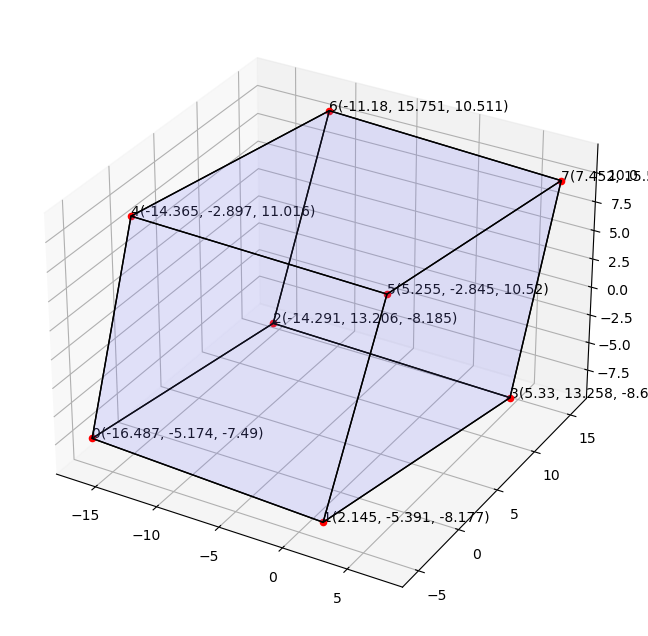

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111, projection='3d')

#vertices = type_atoms[:,2:]

#ax.scatter(vertices[:, 0], vertices[:, 1], vertices[:, 2], color='r', marker='o')#, label='Vertices')
for i in range(8):
    ax.scatter(vertices[i, 0], vertices[i, 1], vertices[i, 2], color='r', marker='o')#, label='Vertices')
    ax.text(vertices[i, 0], vertices[i, 1], vertices[i, 2], f'{i}'+f'({round(vertices[i, 0],3)}, {round(vertices[i, 1],3)}, {round(vertices[i, 2],3)})')
    
poly3d = Poly3DCollection(faces, alpha=.1, linewidths=1, edgecolors='black')
poly3d.set_facecolor([0.5, 0.5, 1, 0.1])  # Face color with some transparency
ax.add_collection3d(poly3d)


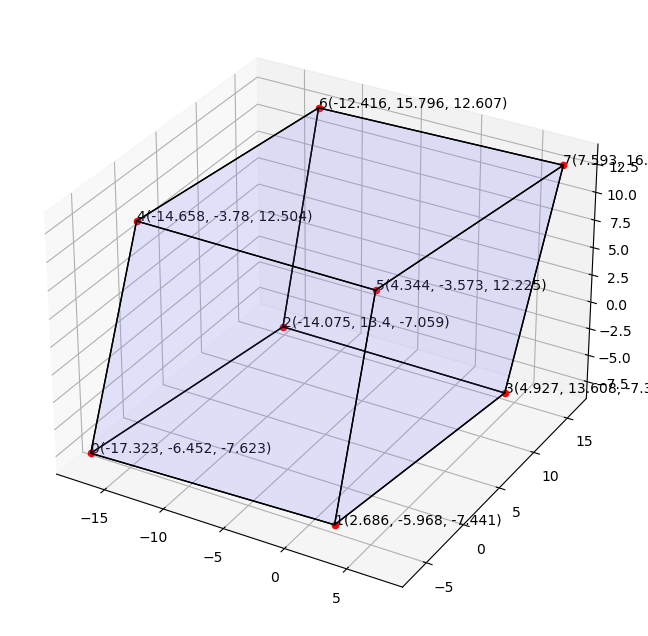

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111, projection='3d')

#vertices = vertices

# Create a Poly3DCollection
for i in range(8):
    ax.scatter(vertices[i, 0], vertices[i, 1], vertices[i, 2], color='r', marker='o')#, label='Vertices')
    ax.text(vertices[i, 0], vertices[i, 1], vertices[i, 2], f'{i}'+f'({round(vertices[i, 0],3)}, {round(vertices[i, 1],3)}, {round(vertices[i, 2],3)})')
    
poly3d = Poly3DCollection(faces, alpha=.1, linewidths=1, edgecolors='black')
poly3d.set_facecolor([0.5, 0.5, 1, 0.1])  # Face color with some transparency
ax.add_collection3d(poly3d)


In [41]:
def plane_equation(p1, p2, p3):
    """Calculate the plane equation Ax + By + Cz + D = 0"""
    v1 = p2 - p1
    v2 = p3 - p1
    normal = np.cross(v1, v2)
    A, B, C = normal
    D = -np.dot(normal, p1)
    return A, B, C, D
    
def is_inside_or_on_rhombohedron(point, corners, tolerance=3):
    """Check if a point is inside or on the planes of the rhombohedron"""
    planes = [
        plane_equation(corners[0], corners[2], corners[1]),
        plane_equation(corners[0], corners[4], corners[2]),
        plane_equation(corners[0], corners[1], corners[4]),
        plane_equation(corners[7], corners[6], corners[5]),
        plane_equation(corners[7], corners[5], corners[3]),
        plane_equation(corners[7], corners[3], corners[6])
    ]

    for A, B, C, D in planes:
        if (A*point[0] + B*point[1] + C*point[2] + D)/np.sqrt(A**2 + B**2 + C**2) > tolerance:
            return False
    return True
# Rhombohedron corners
corners = big_cube
# Function to filter atoms
def filter_atoms_in_or_on_rhombohedron(atoms, corners):
    return [atom for atom in atoms if is_inside_or_on_rhombohedron(atom, corners)]
atoms_inside_or_on = filter_atoms_in_or_on_rhombohedron(data[:,2:], corners)
#print("Atoms inside or on the rhombohedron:")
#print(atoms_inside_or_on)

In [44]:
def find_atom_indices(atoms_inside_or_on, data_array):
    # Convert the list of numpy arrays to a 2D numpy array
    atoms_inside_or_on = np.array([atom for atom in atoms_inside_or_on])
    
    # Extract just the coordinate columns from the data array
    data_coordinates = data[:, 2:5].astype(float)
    
    # Find matching indices
    indices = []
    for atom in atoms_inside_or_on:
        # Find rows where all coordinates match (within a small tolerance)
        matches = np.all(np.isclose(data_coordinates, atom, atol=1e-6), axis=1)
        if np.any(matches):
            # Get the index of the first match
            index = np.where(matches)[0][0]
            indices.append(index)
    
    return indices
    
matching_indices = find_atom_indices(atoms_inside_or_on, data)

#print("Matching indices:", matching_indices)

# Print the full rows for the matching atoms
#for index in matching_indices:
#    print(data[index])

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


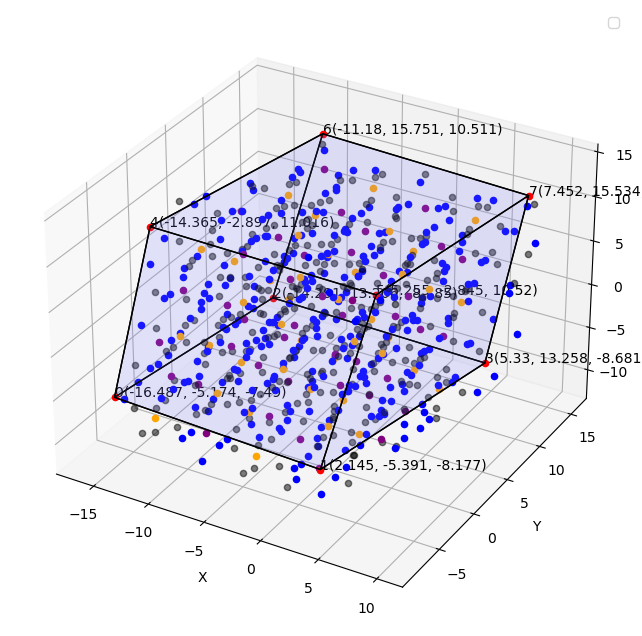

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111, projection='3d')

vertices = big_cube

# Create a Poly3DCollection
for i in range(8):
    ax.scatter(vertices[i, 0], vertices[i, 1], vertices[i, 2], color='r', marker='o')#, label='Vertices')
    ax.text(vertices[i, 0], vertices[i, 1], vertices[i, 2], f'{i}'+f'({round(vertices[i, 0],3)}, {round(vertices[i, 1],3)}, {round(vertices[i, 2],3)})')
    
poly3d = Poly3DCollection(faces, alpha=.1, linewidths=1, edgecolors='black')
poly3d.set_facecolor([0.5, 0.5, 1, 0.1])  # Face color with some transparency
ax.add_collection3d(poly3d)



atoms_inside = np.array(atoms_inside_or_on)
for i in range(len(atoms_inside_or_on)):
    if data[matching_indices][i][1] == 0:
        ax.scatter(data[matching_indices][i][2],data[matching_indices][i][3],data[matching_indices][i][4], color='black', marker='o', alpha=0.5)#, label='Atoms Inside')
    if data[matching_indices][i][1] == 1:
        ax.scatter(data[matching_indices][i][2],data[matching_indices][i][3],data[matching_indices][i][4], color='purple', marker='o')#, label='Atoms Inside')
    if data[matching_indices][i][1] == 2:
        ax.scatter(data[matching_indices][i][2],data[matching_indices][i][3],data[matching_indices][i][4], color='orange', marker='o')#, label='Atoms Inside')
    if data[matching_indices][i][1] == 3:
        ax.scatter(data[matching_indices][i][2],data[matching_indices][i][3],data[matching_indices][i][4], color='blue', marker='o')#, label='Atoms Inside')
    if data[matching_indices][i][1] == 5:
        ax.scatter(data[matching_indices][i][2],data[matching_indices][i][3],data[matching_indices][i][4], color='yellow', marker='o')#, label='Atoms Inside')
#ax.scatter(atoms_inside[:, 0], atoms_inside[:, 1], atoms_inside[:, 2], color='black', marker='o', label='Atoms Inside')


# Set the limits of the plot
#ax.set_xlim([min(vertices[:, 0]), max(vertices[:, 0])])
#ax.set_ylim([min(vertices[:, 1]), max(vertices[:, 1])])
#ax.set_zlim([min(vertices[:, 2]), max(vertices[:, 2])])

# Set labels
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.legend()
# Show the plot
plt.show()


In [46]:
len(atoms_inside_or_on)

739

In [31]:
slected_data = data[matching_indices]
slected_data[:,0] = range(len(slected_data[:,0]))
slected_data[:,0] = slected_data[:,0].astype(int)
slected_data[:,1] = slected_data[:,1].astype(int)

### Step 3: Decide how which atom to fix
For the atom within the sphere (r=4.5 A) of the target_atom

In [47]:
origin = nearest_atom[2:5] 
distance_R = np.linalg.norm(slected_data[:, 2:5] - origin, axis=1)

In [48]:
to_fix = distance_R[distance_R <= 7]
to_relax = distance_R[distance_R > 7]

In [49]:
fix_indices = [np.where(distance_R == element)[0][0] for element in to_fix]

In [50]:
len(fix_indices)

106

In [51]:
vertices=big_cube
# Calculate the lattice vectors
a = vertices[1] - vertices[0]
b = vertices[2] - vertices[0]
c = vertices[4] - vertices[0]

# Calculate the tilt factors
xy = abs(b[0])
xz = abs(c[0])
yz = abs(c[1])

xy,xz,yz

(2.196949, 2.1226819999999975, 2.2764950000000006)

In [52]:
lx = abs(vertices[:,0].min()-vertices[:,0].max())
ly = abs(vertices[:,1].min()-vertices[:,1].max())
lz = abs(vertices[:,2].min()-vertices[:,2].max())

In [53]:
lx,ly,lz

(23.939771999999998, 21.142246, 19.696308)

In [39]:
abs(vertices[:,0].min()-vertices[:,0].max()+(lx-lz)) ,abs(vertices[:,1].min()-vertices[:,1].max()+(ly-lz)) , abs(vertices[:,2].min()-vertices[:,2].max())

(19.696308, 19.696308, 19.696308)

### Step 4: Write the rhombohedron cfg file

In [200]:
def write_cfg_file(filename):
    # Example data for demonstration
    data = slected_data
    for entry in data:
        entry[0] = int(float(entry[0]))+1  # Convert id to int
        entry[1] = int(float(entry[1]))  # Convert type to int

    with open(filename, 'w') as f:
        f.write("BEGIN_CFG\n")
        f.write(" Size\n")
        f.write("    {}\n".format(len(data)))  # Assuming 'Size' is the count of data entries
        f.write(" AtomData:  id type       cartes_x      cartes_y      cartes_z\n")
        for entry in data:
            f.write(" {:>15d} {:>4d} {:>14.6f} {:>14.6f} {:>14.6f}\n".format(
                int(entry[0]), int(entry[1]), float(entry[2]), float(entry[3]), float(entry[4])))
        f.write("END_CFG")

# Usage example:
write_cfg_file("before_3.cfg")

In [54]:

# Extract information
num_atoms = len(slected_data)
num_atom_types = len(np.unique(slected_data[:, 1]))

x_min, x_max = vertices[:,0].min(), vertices[:,0].max()-(lx-lz)
y_min, y_max = vertices[:,1].min(), vertices[:,1].max()-(ly-lz)
z_min, z_max = vertices[:,2].min(), vertices[:,2].max()#-0.5

# Write LAMMPS data file
with open('big_14.data', 'w') as f:
    # Header
    f.write("LAMMPS data file from Python script\n\n")
    
    f.write(f"{num_atoms} atoms\n")
    f.write(f"{num_atom_types} atom types\n\n")
    
    # Box dimensions with tilt factors
    f.write(f"{x_min:.6f} {x_max:.6f} xlo xhi\n")
    f.write(f"{y_min:.6f} {y_max:.6f} ylo yhi\n")
    f.write(f"{z_min:.6f} {z_max:.6f} zlo zhi\n")
    f.write(f"{xy:.6f} {xz:.6f} {yz:.6f} xy xz yz\n\n")
    
    # Atoms section
    f.write("Atoms\n\n")
    
    # Write specified atoms first
    written_atoms = set()
    for i, index in enumerate(fix_indices, 1):
        atom = slected_data[index]
        atom_id = i
        atom_type = int(atom[1]) + 1  # Shifting atom types by 1 as LAMMPS uses 1-based indexing
        x, y, z = atom[2:5]
        f.write(f"{atom_id} {atom_type} {x:.6f} {y:.6f} {z:.6f}\n")
        written_atoms.add(index)
    
    # Write the rest of the atoms
    for i, atom in enumerate(slected_data):
        if i not in written_atoms:
            atom_id = len(written_atoms) + 1
            atom_type = int(atom[1]) + 1  # Shifting atom types by 1 as LAMMPS uses 1-based indexing
            x, y, z = atom[2:5]
            f.write(f"{atom_id} {atom_type} {x:.6f} {y:.6f} {z:.6f}\n")
            written_atoms.add(i)

print("LAMMPS data file 'lammps_data.dat' has been created with specified atom order.")

with open('R_14_center.txt', 'w') as f:
    # Header
    f.write(f"{nearest_atom[2:5][0]} {nearest_atom[2:5][1]} {nearest_atom[2:5][2]}")

LAMMPS data file 'lammps_data.dat' has been created with specified atom order.


In [83]:
import numpy as np

def distance_3d(point1, point2):
    return np.linalg.norm(point1 - point2)

# Assuming your numpy array is called 'data' and has the structure:
# [id, type, x, y, z] for each row

# Check if the first atom is of type 2
if data[0, 1] == 2:
    print(f"The first atom (ID: {data[0, 0]}) is already of type 2.")
else:
    # Find the nearest type 2 atom to (0,0,0)
    origin = np.array([0, 0, 0])
    type_2_atoms = data[data[:, 1] == 2]
    
    if len(type_2_atoms) > 0:
        distances = np.linalg.norm(type_2_atoms[:, 2:5] - origin, axis=1)
        nearest_index = np.argmin(distances)
        nearest_type_2 = type_2_atoms[nearest_index]
        
        distance = distances[nearest_index]
        print(f"The nearest Fe to (0,0,0) is:")
        print(f"ID: {nearest_type_2[0]}")
        print(f"Coordinates: {nearest_type_2[2:5]}")
        print(f"Distance from origin: {distance:.6f}")
    else:
        print("No type 2 atoms found in the data.")

if data[0, 1] == 1:
    print(f"The first atom (ID: {data[0, 0]}) is already of type 1.")
else:
    # Find the nearest Mn atom to the center Fe
    origin = nearest_type_2[2:5]
    type_1_atoms = data[data[:, 1] == 1]
    
    if len(type_1_atoms) > 0:
        distances = np.linalg.norm(type_1_atoms[:, 2:5] - origin, axis=1)
        nearest_index = np.argmin(distances)
        farest_index = np.argmax(distances)
        nearest_type_1 = type_1_atoms[nearest_index]
        farest_type_1 = type_1_atoms[farest_index]
        
        distance = distances[nearest_index]
        print(f"The nearest Mn to (0,0,0) is:")
        print(f"ID: {nearest_type_1[0]}")
        print(f"Coordinates: {nearest_type_1[2:5]}")
        print(f"Distance from origin: {distance:.6f}")

        distance = distances[farest_index]
        print(f"The farest Mn to (0,0,0) is:")
        print(f"ID: {farest_type_1[0]}")
        print(f"Coordinates: {farest_type_1[2:5]}")
        print(f"Distance from origin: {distance:.6f}")
    else:
        print("No type 1 atoms found in the data.")

The nearest Fe to (0,0,0) is:
ID: 86.0
Coordinates: [-0.357256  2.863477  0.881365]
Distance from origin: 3.017273
The nearest Mn to (0,0,0) is:
ID: 85.0
Coordinates: [-0.938845  2.271951 -3.756134]
Distance from origin: 4.711109
The farest Mn to (0,0,0) is:
ID: 327.0
Coordinates: [13.237775 -6.895328  0.880199]
Distance from origin: 16.734968


In [38]:
distances

array([11.46824069,  8.24418833,  4.71110876,  4.97017088,  9.54471034,
        4.80626853,  7.97380795,  8.08406328, 11.64255721, 10.79538454,
       11.53704203,  5.09256234, 10.31899299,  8.50026107,  5.18058121,
        8.20750432,  4.89926041, 10.688888  , 10.50844318])

In [12]:
data[i][2],data[i][3],data[i][4]

0.0

In [18]:
def distance_3d(point1, point2):
    return math.sqrt(sum((a - b) ** 2 for a, b in zip(point1, point2)))

In [19]:
distance_3d(data[0][2:],data[1][2:])

7.810912811040589

In [14]:
i=1
math.sqrt(data[i][2]**2 + data[i][3]**2 + data[i][4]**2)


7.810912811040589

In [6]:
# if (0,0,0) is not Fe, find the nearest Fe
if int(data[0][1])!=2:
    


array([[  1.      ,   2.      ,   0.      ,   0.      ,   0.      ],
       [  2.      ,   0.      ,  -6.073653,  -4.609255,  -1.695838],
       [  3.      ,   1.      ,  -6.154297,  -5.220752,  -4.89101 ],
       ...,
       [261.      ,   0.      ,   1.854557,   4.818994,  -5.513475],
       [262.      ,   3.      ,   3.069006,   4.959647,  -5.372445],
       [263.      ,   0.      ,  -0.965376,  -7.149595,  -5.530755]])

## Cut into cube

In [23]:
out_cube = []
for i in range(big_data.shape[0]):
    if (abs(big_data[i,2:]) > 8).any():
        out_cube.append(i)
in_cube = [num for num in range(big_data.shape[0]) if num not in out_cube]

In [24]:
big_data_cube = big_data[in_cube]

In [25]:
big_data_cube.shape

(295, 5)

## Put the atoms in small to the back of the file

In [45]:
same_line = []
diff_line = []
for i in range(big_data_cube.shape[0]):
    if big_data_cube[i,2:] in small_data[:,2:]:
        same_line.append(i)
    if big_data_cube[i,2:] not in small_data[:,2:]:
        diff_line.append(i)

In [46]:
small_data.shape, big_data_cube.shape, len(same_line), len(diff_line)

((93, 5), (295, 5), 93, 202)

In [47]:
big_data_modify = np.ones(big_data_cube.shape)
for i in range(len(same_line)):
    big_data_modify[i] = big_data_cube[same_line[i]]
for i in range(len(same_line),big_data_cube.shape[1]):
    big_data_modify[i] = big_data_cube[diff_line[i-len(same_line)]]

In [48]:
big_data_modify[:,0] = range(big_data_cube.shape[0])

In [49]:
# Header information
atom_data = big_data_modify
xlo, xhi = -8, 8
ylo, yhi = -8, 8
zlo, zhi = -8, 8
xy, xz, yz = 0, 0, 0
num_atoms = len(atom_data)
num_atom_types = len(np.unique(atom_data[:, 1]))

# Writing to file
filename = 'lammps.data'
with open(filename, 'w') as f:
    # Writing header lines
    f.write("\n")
    f.write(f"{xlo} {xhi} xlo xhi\n")
    f.write(f"{ylo} {yhi} ylo yhi\n")
    f.write(f"{zlo} {zhi} zlo zhi\n")
    f.write(f"{xy} {xz} {yz} xy xz yz\n\n")
    
    f.write(f"{num_atoms} atoms\n")
    f.write(f"{num_atom_types} atom types\n\n")
    
    f.write("Atoms\n\n")
    
    # Writing atom data
    for i in range(num_atoms):
        atom_id = int(atom_data[i, 0])
        atom_type = int(atom_data[i, 1])
        x = atom_data[i, 2]
        y = atom_data[i, 3]
        z = atom_data[i, 4]
        f.write(f"{atom_id} {atom_type} {x} {y} {z}\n")

# Convert Lammps data file to POSCAR

In [1]:
import numpy as np
import pandas as pd
import math
import os
import sys

In [34]:
with open(f"./relaxed.data{p}", 'r') as file:
    lines = file.readlines()

data = {}
reading_atoms = False
atoms = []

for line in lines:
    if "atoms" in line:
        data["num_atoms"] = int(line.split()[0])
    elif "xlo xhi" in line:
        data["xlo"], data["xhi"] = map(float, line.split()[:2])
    elif "ylo yhi" in line:
        data["ylo"], data["yhi"] = map(float, line.split()[:2])
    elif "zlo zhi" in line:
        data["zlo"], data["zhi"] = map(float, line.split()[:2])
    elif "Atoms" in line:
        reading_atoms = True
    elif reading_atoms and line.strip():
        atoms.append(line.split())

data["atoms"] = atoms

In [37]:
line.strip()

'158 0 0 0'

In [ ]:
def parse_lammps_data(file_path):
    with open(file_path, 'r') as file:
        lines = file.readlines()

    data = {}
    reading_atoms = False
    atoms = []

    for line in lines:
        if "atoms" in line:
            data["num_atoms"] = int(line.split()[0])
        elif "xlo xhi" in line:
            data["xlo"], data["xhi"] = map(float, line.split()[:2])
        elif "ylo yhi" in line:
            data["ylo"], data["yhi"] = map(float, line.split()[:2])
        elif "zlo zhi" in line:
            data["zlo"], data["zhi"] = map(float, line.split()[:2])
        elif "Atoms" in line:
            reading_atoms = True
        elif reading_atoms and line.strip():
            atoms.append(line.split())

    data["atoms"] = atoms
    return data

def lammps_to_poscar(data, atom_types, output_file):
    num_atoms = data["num_atoms"]
    atoms = data["atoms"]

    xlo, xhi = data["xlo"], data["xhi"]
    ylo, yhi = data["ylo"], data["yhi"]
    zlo, zhi = data["zlo"], data["zhi"]

    lx = xhi - xlo
    ly = yhi - ylo
    lz = zhi - zlo

    # Assuming orthogonal box
    a = [lx, 0, 0]
    b = [0, ly, 0]
    c = [0, 0, lz]

    atom_count = {atom: 0 for atom in atom_types}
    atom_positions = {atom: [] for atom in atom_types}

    for atom in atoms:
        atom_type = int(atom[1])
        x, y, z = map(float, atom[2:5])
        atom_positions[atom_types[atom_type - 1]].append([x, y, z])
        atom_count[atom_types[atom_type - 1]] += 1

    with open(output_file, 'w') as file:
        file.write("Converted from LAMMPS data file\n")
        file.write("1.0\n")
        file.write(f"    {a[0]:.6f} {a[1]:.6f} {a[2]:.6f}\n")
        file.write(f"    {b[0]:.6f} {b[1]:.6f} {b[2]:.6f}\n")
        file.write(f"    {c[0]:.6f} {c[1]:.6f} {c[2]:.6f}\n")

        file.write(" ".join(atom_types) + "\n")
        file.write(" ".join(map(str, [atom_count[atom] for atom in atom_types])) + "\n")
        file.write("Cartesian\n")

        for atom in atom_types:
            for pos in atom_positions[atom]:
                file.write(f"{pos[0]:.6f} {pos[1]:.6f} {pos[2]:.6f}\n")

In [ ]:
if __name__ == "__main__":
    if len(sys.argv) != 2:
        print("Usage: python script.py <file_index>")
        sys.exit(1)

    p = int(sys.argv[1])
    atom_types = ["C", "Mn", "Fe", "N", "Na"]
    lammps_file_path = f"./relaxed.data{p}"
    output_poscar_file = f"POSCAR{p}"
    data = parse_lammps_data(lammps_file_path)
    lammps_to_poscar(data, atom_types, output_poscar_file)
    print(f'{lammps_file_path} has been converted to {output_poscar_file}')


In [15]:
p=0
atom_types = ["C", "Mn", "Fe", "N", "Na"]
lammps_file_path = f"./relaxed.data{p}"
output_poscar_file = f"POSCAR{p}"
data = parse_lammps_data(lammps_file_path)
lammps_to_poscar(data, atom_types, output_poscar_file)

IndexError: list index out of range

In [26]:
num_atoms = data["num_atoms"]
atoms = data["atoms"]

xlo, xhi = data["xlo"], data["xhi"]
ylo, yhi = data["ylo"], data["yhi"]
zlo, zhi = data["zlo"], data["zhi"]

lx = xhi - xlo
ly = yhi - ylo
lz = zhi - zlo

# Assuming orthogonal box
a = [lx, 0, 0]
b = [0, ly, 0]
c = [0, 0, lz]

atom_count = {atom: 0 for atom in atom_types}
atom_positions = {atom: [] for atom in atom_types}

for atom in atoms:
    atom_type = int(atom[1])
    x, y, z = map(float, atom[2:5])
    atom_positions[atom_types[atom_type - 1]].append([x, y, z])
    atom_count[atom_types[atom_type - 1]] += 1

IndexError: list index out of range

In [27]:
data["num_atoms"]

188

In [28]:
atoms = data["atoms"]

In [31]:
data["atoms"]

[['88',
  '2',
  '-5.580255467036304',
  '-5.899220591641569',
  '-5.912671603872662',
  '0',
  '0',
  '0'],
 ['127',
  '4',
  '-3.7587694057575955',
  '-5.6283940194962545',
  '-3.8835263333640113',
  '0',
  '0',
  '0'],
 ['164',
  '3',
  '-1.1384386493992074',
  '-5.235060429439575',
  '-5.278173016161047',
  '0',
  '0',
  '0'],
 ['91',
  '1',
  '-2.9157336579439836',
  '-5.748318807737865',
  '-4.7309781780971285',
  '0',
  '0',
  '0'],
 ['163',
  '1',
  '-1.0099360265499264',
  '-4.774906687889524',
  '-7.469777151521791',
  '0',
  '0',
  '0'],
 ['87',
  '1',
  '-6.315159832195504',
  '-4.668187779407013',
  '-1.6908434204512635',
  '0',
  '0',
  '0'],
 ['89',
  '4',
  '-6.539334241425675',
  '-4.521678974534978',
  '-2.8112869349614584',
  '0',
  '0',
  '0'],
 ['90',
  '3',
  '-5.8450802799175765',
  '-5.029247819858733',
  '-0.019437043375862273',
  '0',
  '0',
  '0'],
 ['126',
  '1',
  '-5.328876407906434',
  '-6.981026595151386',
  '-0.5479167339209512',
  '0',
  '0',
  '0'],
 

In [21]:
atom_types

['C', 'Mn', 'Fe', 'N', 'Na']

In [24]:
atom[0]

'Velocities'

In [25]:
atom_positions 

{'C': [[-2.9157336579439836, -5.748318807737865, -4.7309781780971285],
  [-1.0099360265499264, -4.774906687889524, -7.469777151521791],
  [-6.315159832195504, -4.668187779407013, -1.6908434204512635],
  [-5.328876407906434, -6.981026595151386, -0.5479167339209512],
  [-3.6029700000000005, -4.605796, -0.46641400000000055],
  [-0.5335390000000015, -5.54422, -3.3237579999999993],
  [-5.089496202624818, -5.129888417242947, 1.650515711698477],
  [-0.6032990000000003, -4.043439, 2.892765],
  [-1.703624670455743, -4.488373242677755, 5.038306070477329],
  [-3.7863485042480005, -0.08415281845045058, -5.5952241020561875],
  [-5.581868340213864, -2.1376417487403283, -5.392667151359479],
  [-1.3045650000000002, -3.572779, -4.529884],
  [-4.988641, -0.7601139999999995, -3.1477030000000004],
  [-5.638243, -3.130224, 0.3541470000000002],
  [-1.718398000000001, -0.34087100000000037, 0.3688580000000008],
  [-4.210497, -1.1182690000000002, 4.404142],
  [-0.2122050000000003, -2.3975869999999997, 5.143069

In [41]:
import sys

def parse_lammps_dump(file_path):
    with open(file_path, 'r') as file:
        lines = file.readlines()

    atoms = []
    box_bounds = []
    atom_section = False

    for line in lines:
        if "ITEM: TIMESTEP" in line:
            timestep = int(lines[lines.index(line) + 1].strip())
        elif "ITEM: NUMBER OF ATOMS" in line:
            num_atoms = int(lines[lines.index(line) + 1].strip())
        elif "ITEM: BOX BOUNDS" in line:
            for i in range(3):
                box_bounds.append(list(map(float, lines[lines.index(line) + 1 + i].strip().split())))
        elif "ITEM: ATOMS" in line:
            atom_section = True
        elif atom_section:
            atoms.append(list(map(float, line.strip().split())))

    return {
        "timestep": timestep,
        "num_atoms": num_atoms,
        "box_bounds": box_bounds,
        "atoms": atoms
    }

def lammps_dump_to_poscar(data, atom_types, output_file):
    num_atoms = data["num_atoms"]
    atoms = data["atoms"]
    box_bounds = data["box_bounds"]

    xlo, xhi = box_bounds[0][:2]
    ylo, yhi = box_bounds[1][:2]
    zlo, zhi = box_bounds[2][:2]

    lx = xhi - xlo
    ly = yhi - ylo
    lz = zhi - zlo

    a = [lx, 0, 0]
    b = [0, ly, 0]
    c = [0, 0, lz]

    atom_count = {atom: 0 for atom in atom_types}
    atom_positions = {atom: [] for atom in atom_types}

    for atom in atoms:
        atom_id, atom_type, x, y, z = atom
        atom_type = int(atom_type)
        atom_positions[atom_types[atom_type - 1]].append([x, y, z])
        atom_count[atom_types[atom_type - 1]] += 1

    with open(output_file, 'w') as file:
        file.write("Converted from LAMMPS dump file\n")
        file.write("1.0\n")
        file.write(f"    {a[0]:.6f} {a[1]:.6f} {a[2]:.6f}\n")
        file.write(f"    {b[0]:.6f} {b[1]:.6f} {b[2]:.6f}\n")
        file.write(f"    {c[0]:.6f} {c[1]:.6f} {c[2]:.6f}\n")

        file.write(" ".join(atom_types) + "\n")
        file.write(" ".join(map(str, [atom_count[atom] for atom in atom_types])) + "\n")
        file.write("Cartesian\n")

        for atom in atom_types:
            for pos in atom_positions[atom]:
                file.write(f"{pos[0]:.6f} {pos[1]:.6f} {pos[2]:.6f}\n")

if __name__ == "__main__":
    if len(sys.argv) != 2:
        print("Usage: python script.py <file_index>")
        sys.exit(1)

    p = 0
    atom_types = ["C", "Mn", "Fe", "N", "Na"]  # Example atom types
    lammps_file_path = f"./relaxed.dump{p}"
    output_poscar_file = f"POSCAR{p}"
    data = parse_lammps_dump(lammps_file_path)
    lammps_dump_to_poscar(data, atom_types, output_poscar_file)
    print(f'{lammps_file_path} has been converted to {output_poscar_file}')


Usage: python script.py <file_index>


SystemExit: 1

In [42]:
p = 0
atom_types = ["C", "Mn", "Fe", "N", "Na"]  # Example atom types
lammps_file_path = f"./relaxed.dump{p}"
output_poscar_file = f"POSCAR{p}"
data = parse_lammps_dump(lammps_file_path)
lammps_dump_to_poscar(data, atom_types, output_poscar_file)
print(f'{lammps_file_path} has been converted to {output_poscar_file}')


./relaxed.dump0 has been converted to POSCAR0


In [60]:
def convert_dump_to_cfg(dump_file, cfg_file):
    with open(dump_file, 'r') as f:
        lines = f.readlines()

    # Extract number of atoms
    num_atoms = int(lines[3].split()[0])

    # Prepare output to write to cfg file
    with open(cfg_file, 'w') as f:
        f.write("BEGIN_CFG\n")
        f.write(f" Size\n    {num_atoms}\n")
        f.write(" AtomData:  id type       cartes_x      cartes_y      cartes_z\n")

        # Extract atom data and write to cfg file
        i=1
        for line in lines[9:]:
            if line.strip().startswith("ITEM:"):
                break
            if line.strip() == "":
                continue
            atom_info = line.split()
            atom_id = i
            atom_type = int(atom_info[1])-1
            x = float(atom_info[2])
            y = float(atom_info[3])
            z = float(atom_info[4])
            f.write(f"{'{:>7}'.format(atom_id)}{'{:>5}'.format(atom_type)}")
            f.write(f"{'{:>14.6f}'.format(x)}{'{:>14.6f}'.format(y)}{'{:>14.6f}'.format(z)}\n")
            i+=1

        f.write("END_CFG\n")
        
if __name__ == "__main__":
    if len(sys.argv) != 2:
        print("Usage: python script.py <file_index>")
        sys.exit(1)

    p = int(sys.argv[1])
    lammps_dump_path = f"./relaxed.dump{p}"
    output_cfg_file = f"after.cfg{p}"
    onvert_dump_to_cfg(lammps_dump_path, output_cfg_file)
    print(f'{lammps_dump_path} has been converted to {output_cfg_file}')


In [51]:
atom_info

['-7.5000000000000000e+00', '7.5000000000000000e+00', '0.0000000000000000e+00']